# MILESTONE 2
**Link Dashboard :** *https://public.tableau.com/views/M2_17926637818820/Visualisasi?:language=en-GB&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link*

## I. PERKENALAN
**Nama      :** Khoizuron Syakira\
**Batch     :** CODA RMT-023\
**Objektif  :** Notebook ini dibuat untuk menganalisis pola kriminalitas pencurian (Theft) dalam waktu 1 tahun terakhir di Kota Chicago. Menggunakan data dari BigQuery yang di proses dalam SQL dan Python lalu diberikan visualisasi data, statistik deskriptif dan uji hipotesis inferensial untuk merumuskan rekomendasi titik-titik patroli kepolisian yang lebih efektif.


## II. IDENTIFIKASI MASALAH
**Klien :** Kepolisian Chicago (*Chicago Police Department*)
### Latar Belakang
Karena kepolisian chicago memiliki personil atau staff yang terbatas maka sebuah tantangan bagi mereka untuk mengurangi persentase kejahatan. Oleh karena itu, dibutuhkan alokasi untuk patroli di area-area yang memang memiliki persentase kejahatan yang tinggi. Terutama di primary type case seperti theft dari data 1 tahun terakhir. Hal ini bertujuan agar operasi patroli dapat difokuskan pada titik-titik dan waktu yang paling krusial
### Problem Statement (*SMART*)
Mengidentifikasi 5 community area di chicago dengan jumlah pencurian terbanyak selama 1 tahun terakhir (Oktober 2025-present) dalam 4 minggu masa analisis, untuk merekomendasikan evaluasi penempatan patroli harian guna menekan angka kasus pencurian sebesar 10% pada bulan berikutnya.
### Penjabaran Key Question:
    1. Bagaimana tren pergerakan bulanan kasus pencurian di Chicago?
    2. Pada waktu dan hari apa kasus pencurian paling marak terjadi?
    3. Community Area mana saja yang paling rawan beserta tipe lokasi yang     
       paling dominannya?
    4. Berapa perbandingan jumlah kasus pencurian antar kuartal dalam 1 tahun
       terakhir untuk mengevaluasi kapan terjadinya lonjakan kasus tertinggi?
    5. Bagaimana karakteristik sebaran dan tingkat fluktuasi (outlier) harian
       kasus pencurian yang terjadi khusus di jalan publik (Street)?
    6. Apakah ada perbedaan pada Arrest rate antara lokasi Publik
       (Street/Sidewalk) dengan lokasi privat (Residence/Apartment)?



## III. PENGAMBILAN DATA (DATA LOADING)

Data mentah diambil dari *database* publik Google BigQuery ('bigquery-public-data.chicago_crime.crime'). Mengingat total populasi kasus *Theft* dalam rentang 1 tahun terakhir sangat besar, pengambilan data dilakukan menggunakan teknik *Random Sampling* sebanyak 10.000 baris

Teknik ini dilakukan guna proses data analisis di Python menjadi lebih efisien, dengan tetap mempertahankan proporsi dan karakteristik dari populasi

**Query SQL**
```
SELECT 
    unique_key, 
    case_number, 
    date, 
    block, 
    primary_type, 
    location_description, 
    arrest, 
    district, 
    ward, 
    community_area
FROM 
    `bigquery-public-data.chicago_crime.crime`
WHERE 
    date >= TIMESTAMP('2025-10-01')
    AND primary_type = 'THEFT'
ORDER BY 
    RAND()
LIMIT 10000;
```

### 2.1 Penjelasan Pemilihan Kolom

Untuk memastikan analisis sesuai dengan perumusan masalah, dari beberapa kolom mentah yang disediakan data BigQuery, hanya 10 kolom yang ditarik. Pemilihan kesepuluh kolom ini digunakan untuk menjawab 6 Key Question di atas:

**1. Dimensi Identitas Kasus**
- **'unique_key' & 'case_number':**
    Berfungsi sebagai primary key unik untuk setiap kasus. Kolom ini krusial untuk
    menghitung total insiden tanpa takut terjadi duplikasi data
- **'primary_type':**
    Sebagai validasi utama bahwa seluruh sampel data yang diambil dan dianalisis terfokuskan
    pada kasus pencurian (*THEFT*)

**2. Dimensi Waktu**
- **'date':**
    Kolom paling krusial untuk analisis deret waktu. Akan diekstrak menjadi bulan, kuartal,
    hari dan jam sehingga bisa menjawab pertanyaan dari tren bulanan

**3. Dimensi Karakteristik & Status Hukum**
- **'location_description':**
    Menjelaskan tipe 'Tempat Kejadian Perkara' (TKP). Sangat esensial untuk mencari tipe
    lokasi paling dominan, memfilter kasus khusus di jalanan, serta memisahkan kategori
    lokasi publik vs privat untuk uji hipotesis.
- **'arrest':**
    Status dimana pelaku apakah berhasil ditangkap atau tidak ('True/False'). Akan digunakan 
    secara khusus untuk menghitung persentase efektivitas penangkapan dalam uji statistik 
    inferensial
    
**4. Dimensi Wilayah Geografis & Administratif**
- **'community_area':**
    Pembagian area makro di Chicago. Menjadi kunci untuk menjawab pertanyaan mengenai 5
    wilayah paling rawan pencurian
- **'district', 'ward', & 'block':**
    Melengkapi 'community_area' sebagai detail lokasi yang lebih mikro. Jika dari hasil
    analisis ditemukan *Community Area* yang rawan, kepolisian dapat membedah lebih dalam ke
    level Distrik atau Blok mana yang butuh patroli lebih.


## IV. DATA CLEANING
Pada tahapan ini , data hasil eksekusi di BigQuery akan dimuat ke dalam dataframe Pandas. Akan dilanjutkan untuk data handling seperti struktur data, penyesuaian tipe data, serta penanganan nilai kosong dan duplikasi data untuk memastikan agar data bisa dianalisis secara efisien.

In [13]:
# Import Library
import pandas as pd
from scipy import stats
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

#Mengabaikan warning agar notebook lebih rapih
warnings.filterwarnings('ignore')

#Load Dataset CSV
df = pd.read_csv('RANDOM_SAMP_CHICAGO.csv')

#Menampilkan 5 baris pertama untuk melihat bentuk data
df.head()

,unique_key,case_number,date,block,primary_type,location_description,arrest,district,ward,community_area
0,14196793,JK254252,2026-05-14 11:00:00.000000 UTC,046XX W IRVING PARK RD,THEFT,PARKING LOT / GARAGE (NON RESIDENTIAL),False,17,45.0,15.0
1,14231326,JK295628,2026-06-13 23:45:00.000000 UTC,015XX W SUPERIOR ST,THEFT,STREET,False,12,1.0,24.0
2,14231179,JK296199,2026-06-11 12:15:00.000000 UTC,050XX N SHERIDAN RD,THEFT,APARTMENT,False,20,48.0,3.0
3,14316080,JK398737,2026-09-02 07:45:00.000000 UTC,033XX W BELMONT AVE,THEFT,CTA BUS STOP,False,14,35.0,21.0
4,14035842,JJ497524,2025-11-20 17:00:00.000000 UTC,022XX W ARTHUR AVE,THEFT,RESIDENCE - YARD (FRONT / BACK),False,24,50.0,2.0


Karena tadi kita mengambil data secara acak menggunakan RAND() di SQL, baris datanya pasti tidak berurutan secara waktu. Selain itu kolom tanggal dari BigQuery biasanya terbaca sebagai string sehingga harus diubah menjadi tipe datetime

In [14]:
#Mengubah tipe data kolom 'date' menjadi tipe 'datetime'
df['date'] = pd.to_datetime(df['date'])

#Memfilter agar 12 bulan penuh dari (oktober 2025 - september 2026) lalu mengurutkannya dan direset index nya
df = df[(df['date'] >= '2025-10-01') & (df['date'] < '2026-10-01')].copy()
df = df.sort_values('date').reset_index(drop=True)

#Mengecek kembali informasi detail dari dataframe (df) seperti jumlah baris, kolom, dan tipe data yang sudah diubah.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9977 entries, 0 to 9976
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   unique_key            9977 non-null   int64              
 1   case_number           9977 non-null   str                
 2   date                  9977 non-null   datetime64[us, UTC]
 3   block                 9977 non-null   str                
 4   primary_type          9977 non-null   str                
 5   location_description  9976 non-null   str                
 6   arrest                9977 non-null   bool               
 7   district              9977 non-null   int64              
 8   ward                  9975 non-null   float64            
 9   community_area        9975 non-null   float64            
dtypes: bool(1), datetime64[us, UTC](1), float64(2), int64(2), str(4)
memory usage: 1.1 MB


Dari hasil penanganan data diatas kita harus menangani missing values dan penyesuaian tipe data lagi. Berdasarkan hasil 'df.info()' di atas, ditemukan bahwa ada dua hal yang perlu diubah yaitu:

1. Adanya missing values pada 2 baris data pada kolom 'ward' dan 'community_area' dan 1 baris di kolom 'location_description'
2. Tidak sesuainya tipe data pada kolom 'ward' dan 'community_area' sehingga berubah menjadi
   tipe desimal ('float64'). Sedangkan kedua kolom ini berisi kode wilayah kota Chicago yang
   sifatnya kategorikal bukan angka ukuran.

Tindakan selanjutnya adalah:
1. Drop missing values karena jumlah data kosong sangat minim yaitu hanya 2 baris
2. Konversi tipe data setelah bersih dari missing values menjadi tipe string agar bisa
   dijadikan identitas kategori wilayah kota Chicago.

In [15]:
#Mneghappus baris nilai kosong di kolom 'ward' dan 'community_area'
df = df.dropna(subset=['ward', 'community_area', 'location_description'])

#mengubah tipe data dari float menjadi string
df['ward'] = df['ward'].astype(str)
df['community_area'] = df['community_area'].astype(str)

#cek kembali untuk memastikan data sudah bersih
print(f"Total_Rows_After_Cleaning: {len(df)}")
df.info()

Total_Rows_After_Cleaning: 9974
<class 'pandas.DataFrame'>
Index: 9974 entries, 0 to 9976
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   unique_key            9974 non-null   int64              
 1   case_number           9974 non-null   str                
 2   date                  9974 non-null   datetime64[us, UTC]
 3   block                 9974 non-null   str                
 4   primary_type          9974 non-null   str                
 5   location_description  9974 non-null   str                
 6   arrest                9974 non-null   bool               
 7   district              9974 non-null   int64              
 8   ward                  9974 non-null   str                
 9   community_area        9974 non-null   str                
dtypes: bool(1), datetime64[us, UTC](1), int64(2), str(6)
memory usage: 1.3 MB


Setelah mengecek *missing values* pastikan tidak ada data duplikat dari data kita, ini langkah terakhir dalam pembersihan data sebelum dianalisa

In [16]:
#Mengecek jumlah data duplikat
total_duplicate = df.duplicated().sum()
print(f"Total_Duplicated_Rows: {total_duplicate}")

#Menghapus data duplikat
if total_duplicate > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicated Data Erased")

Total_Duplicated_Rows: 0


Karena data sudah dipastikan tidak ada yang terduplikasi kita bisa memisahkan komponen waktu dari kolom 'date' untuk mempermudah analisis tren bulanan dan pembuatan *Heatmap* waktu (hari & jam) pada tahap eksplorasi data. Sehingga nantinya ada 3 kolom baru yaitu *Month, Day, dan Hour*.

In [17]:
#Memisahkan komponen waktu dari kolom 'date'
df['month'] = df ['date'].dt.to_period('M') #akan ada kolom dengan format Year-Month
df['day_name'] = df ['date'].dt.day_name()  #akan ada kolom dengan nama hari
df['hour'] = df ['date'].dt.hour            #akan ada kolom dengan angka jam

#Mengecek 50 baris pertama untuk melihat kolom yang baru dibuat
df[['date', 'month', 'day_name', 'hour']].head(50)

,date,month,day_name,hour
0,2025-10-01 00:00:00+00:00,2025-10,Wednesday,0
1,2025-10-01 00:00:00+00:00,2025-10,Wednesday,0
2,2025-10-01 00:00:00+00:00,2025-10,Wednesday,0
3,2025-10-01 00:33:00+00:00,2025-10,Wednesday,0
4,2025-10-01 00:34:00+00:00,2025-10,Wednesday,0
5,2025-10-01 03:00:00+00:00,2025-10,Wednesday,3
6,2025-10-01 03:35:00+00:00,2025-10,Wednesday,3
7,2025-10-01 04:57:00+00:00,2025-10,Wednesday,4
8,2025-10-01 05:00:00+00:00,2025-10,Wednesday,5
9,2025-10-01 06:00:00+00:00,2025-10,Wednesday,6


Melalui peninjauan 50 baris pertama setelah pemisahan komponen waktu, hari, dan tanggal menunjukkan hasil yang presisi dan memberikan konteks yang kuat terhadap dataset yang ada.

1. Tingkat Insiden: dimana ini terekam berulang kali hingga baris 45. Hal ini menunjukkan bahwa setiap baris merepresentasikan satu laporan pencurian, bukan akumulasi per harian
2. Algoritma merespons bahwa pergantian tanggal secara akurat dapat terlihat dari baris 45 ke 46 dimana wednesday malam menjadi thursday dini hari

Variasi waktu kejadian dari tengah malam hingga memvalidasi dimensi waktu untuk membedah tren kejahatan bulanan

## V. ANALISIS DAN PERHITUNGAN

Pada tahapan ini kita akan mengeksplorasi dataset yang telah dibersihkan untuk menjawab *key question* yang telah dirumuskan

### V.I Tren Bulanan Kasus Pencurian
**Pertanyaan: Bagaimana tren pergerakan bulanan kasus pencurian di Chicago selama 1 tahun terakhir?**

Untuk menjawab pertanyaan ini, data harus dikelompokkan berdasarkan bulan kejadian terlebih dahulu, kemudian akan kita visualisasikan menggunakan *Line Chart* agar fluktuasi jumlah kasus dari bulan ke bulan dapat terlihat dengan jelas

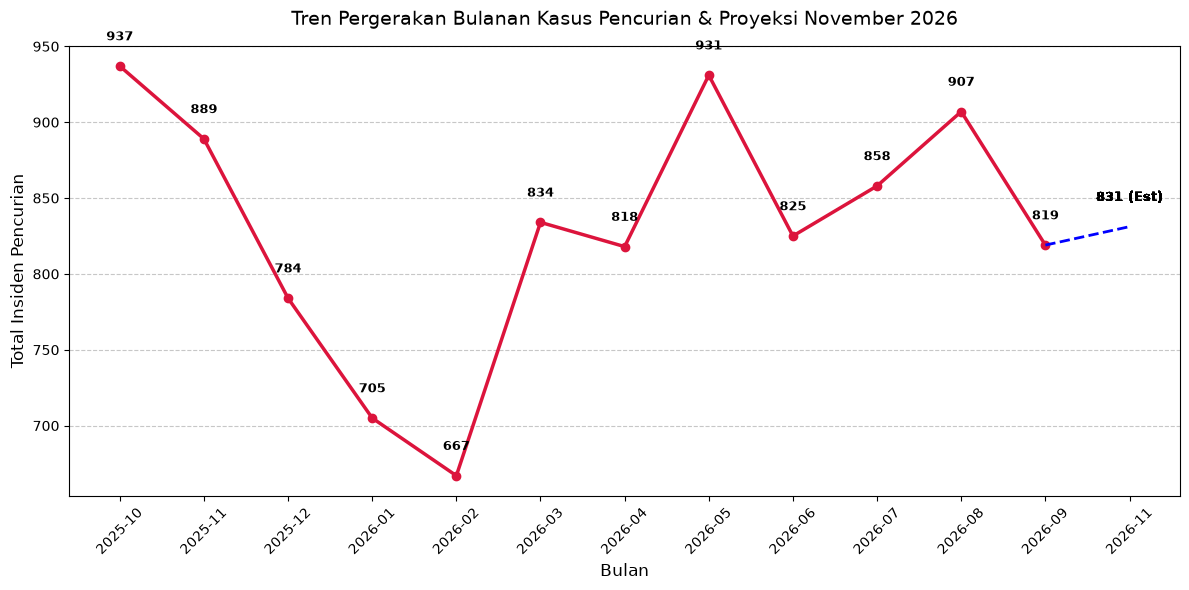

Ringkasan Angka Pencurian Bulanan


,month_str,total_cases
0,2025-10,937
1,2025-11,889
2,2025-12,784
3,2026-01,705
4,2026-02,667
5,2026-03,834
6,2026-04,818
7,2026-05,931
8,2026-06,825
9,2026-07,858


In [18]:
#Memastikan kolom 'date' bertipe datetime
df['date'] = pd.to_datetime(df['date'])

#Memastikan kolom 'month' sudah terbentuk di df
df['month'] = df['date'].dt.to_period('M')

#Agregasi jumlah kasus per bulan
monthly_cases = (df.groupby('month').size().reset_index(name='total_cases'))

#Mengkonversi tipe data kolom 'month' dari tipe Period ke tipe string agat tidak error saat dirender matplotlib
monthly_cases['month_str'] = monthly_cases['month'].astype(str)

#Menghitung angka proyeksi November 2026 (Rata-rata 1 tahun)
projection_nov = monthly_cases['total_cases'].mean()

#Mengambil data titik bulan terakhir
last_month =  monthly_cases['month_str'].iloc[-1]
last_value =  monthly_cases['total_cases'].iloc[-1]

#Menyiapkan ukuran kanvas grafik
plt.figure(figsize=(12,6))

#Membuat line chart data aktual
plt.plot(
    monthly_cases['month_str'],
    monthly_cases['total_cases'],
    marker='o',
    color='crimson',
    linewidth=2.5,
    label='Data Aktual'
)

#Membuat line chart proyeksi November 2026
plt.plot(
    [last_month, '2026-11'],
    [last_value, projection_nov],
    linestyle='--',
    color='blue',
    linewidth=2,
    label='Proyeksi Nov 2026'
)

#Menambahkan data label angka pada titik aktual
for i, row in monthly_cases.iterrows():
    plt.text(
        i,
        row['total_cases'] + 15,
        str(row['total_cases']),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

#Menambahkan data label angka khusus pada titik proyeksi November
    plt.text(
        '2026-11',
        projection_nov + 15,
        f'{round(projection_nov)} (Est)',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.title('Tren Pergerakan Bulanan Kasus Pencurian & Proyeksi November 2026', fontsize=14, pad=15)
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Total Insiden Pencurian', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#Menampilkan tabel untuk ringkasan statistik bulanan
print("Ringkasan Angka Pencurian Bulanan")
display(monthly_cases[['month_str', 'total_cases']])


**Analisa dan insight dari tren bulanan kasus pencurian:**
1. **Puncak Kejadian**
    - Kasus pencurian tertinggi terjadi pada Okt 2025 = 937 kasus, Mei 2026 = 931 kasus, dan Agustus 2026 = 907 kasus
    - Secara umum, bulan-bulan dengan cuaca hangat yaitu musim semi hingga akhir musim panas menunjukkan bahwa angka pencurian konsisten tinggi di angka 800-900 kasus

2. **Penurunan Kasus di Musim Dingin**
    - Terjadi tren dimana penurunan bertahap dari Okt 2025 (937 kasus) hingga mencapai titik terendah pada bulan Februari 2026 (667 kasus)
    - Hal ini bisa diasumsikan karena dipengaruhi oleh faktor cuaca yaitu musim dingin di Chicago sehingga aktivitas dan mobilitas masyarakat di ruang publik berkurang

3. **Lonjakan Kasus pada Musim Panas/Semi**
    - Memasukin bulan Maret 2026 hingga Mei 2026, angka kasus melonjak tinggi kembali dari angka 667 kasus menjadi 931 kasus. Kenaikan ini sejalan dengan meningkatnya mobilitas masyarakat di ruang publik pada musim semi/panas

3. **Proyeksi Kasus November 2026**
    - Berdasarkan hasil kalkulasi diatas *statistical baseline* dimana rata-rata historis dalam 1 tahun terakhir, total kasus pencurian pada bulan **November 2026 akan mencapa ~831 kasus**
    - Angka ini bergerak naik tipis dari realisasi September 2026 yang tercatat sebanyak 819 kasus seiring mulai meningkatnya mobilitas publik menjelang kuartal akhir Q4.

Sehingga dari *insight* tersebut kita berlari ke pertanyaan selanjutnya yaitu detail kasus pencurian kapan waktu dan hari rawan terjadinya kasus pencurian.

### V.2 Analisis Waktu dan Hari Kejadian
**Pertanyaan: Pada waktu dan hati apa kasus pencurian marak terjadi?**

Untuk itu kita perlu mengombinasikan variabel ('day_name') dan jam kejadian ('hour') ke dalam sebuah matriks silang

Visualisasi berbentuk heatmap akan dilakukan agar kepolisian bisa mengidentifikasi *hotspot* waktu (jam-jam puncak dan hari rawan) untuk mengoptimalisasikan jadwal patroli harian

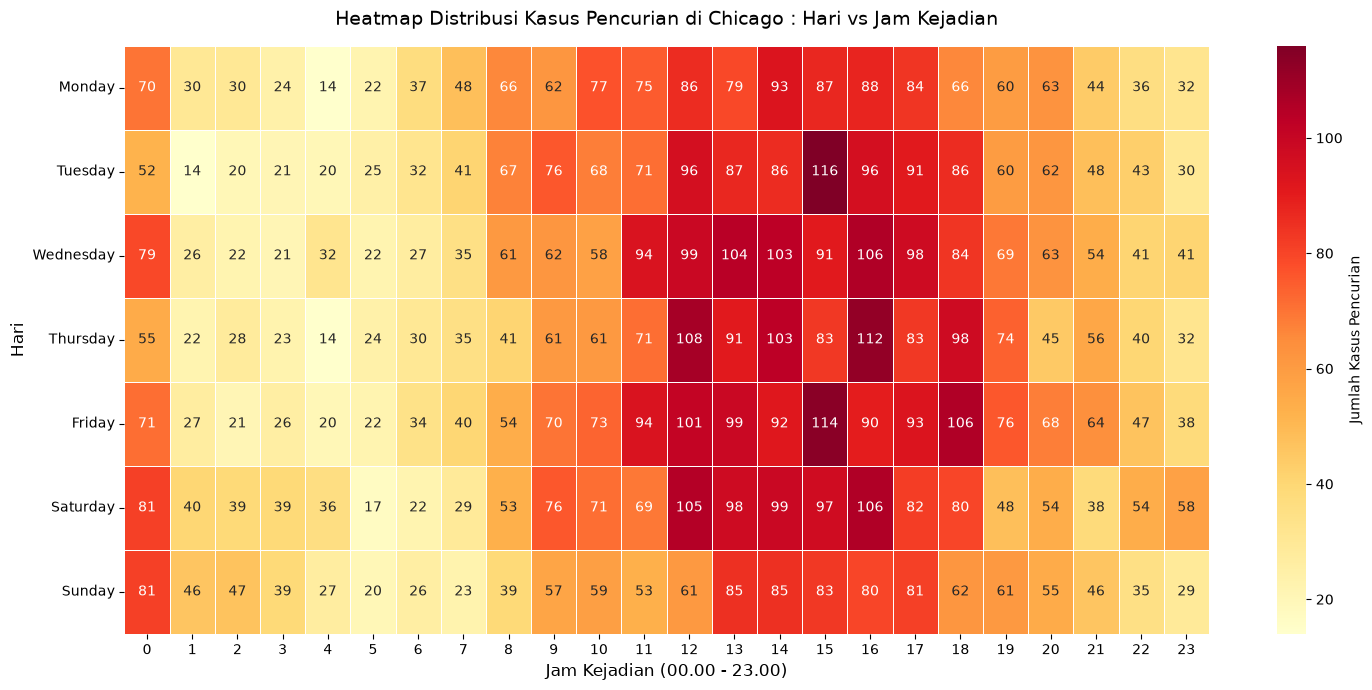

3 Jam Puncak Kejahatan Pencurian
Jam16:00 : 678 kasus
Jam15:00 : 671 kasus
Jam14:00 : 661 kasus

 Ringkasan Total Kasus per Hari


,day_name,total_cases
0,Monday,1373
1,Tuesday,1408
2,Wednesday,1492
3,Thursday,1390
4,Friday,1540
5,Saturday,1491
6,Sunday,1280


In [19]:
#Mengatur urutan hari urut dari Senin-Minggu
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

#Membuat tabel *crosstab* antara Hari dan Jam Kejadian
heatmap_data = pd.crosstab(df['day_name'], df['hour']).reindex(days_order)

#Membuat grafik Heatmap
plt.figure(figsize=(15, 7))
sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    annot=True,
    fmt='d',
    linewidths=0.5,
    cbar_kws={'label': 'Jumlah Kasus Pencurian'}
)

plt.title ('Heatmap Distribusi Kasus Pencurian di Chicago : Hari vs Jam Kejadian', fontsize=14, pad=15)
plt.xlabel('Jam Kejadian (00.00 - 23.00)', fontsize = 12)
plt.ylabel('Hari', fontsize = 12)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#Menampilkan ringkasan jam dan hari paling rawan
print('3 Jam Puncak Kejahatan Pencurian')
top_hours = df['hour'].value_counts().head(3)
for hour, count in top_hours.items():
    print(f"Jam{hour:02d}:00 : {count} kasus")

print("\n Ringkasan Total Kasus per Hari")
display(df['day_name'].value_counts().reindex(days_order).reset_index(name='total_cases'))

**Analisa dan insight dari waktu dan hari kejadian:**
1. **Jam Puncak Kejadian**
    - Kasus pencurian paling marak terjadi pada rentang siang hari menuju sore dengan puncak waktu di 16.00 (678 kasus), 15.00 (671 kasus), 14.00 (661 kasus)
    - Ini sejalan dengan asumsi kita di awal yaitu jam sibuk masyarakat di ruang publik terjadi pada siang-sore hari seperti waktu istirahat, jam pulang sekolah, dan jam pulang kantor.

2. **Hari Paling Rawan**
    - Hari jumat menjadi hari dengan angka tertinggi yaitu 1540 kasus disusul dengan hari rabu (1492 kasus) dan sabtu (1491 kasus)
    - Kenaikan pada hari Jumat dan Sabtu berkaitan erat dengan tingginya mobilitas masyarakat serta peningkatan aktivitas menjelang akhir pekan
    - Hari minggu mejadi hari dengan frekuensi terendah yaitu 1280 kasus 

3. **Anomali Jam 00:00**
    - Adanya lonjakan laporan pada jam 00:00 (tengah malam) di hampir seluruh hari (berkisar 52-81 kasus per hari) dibandingkan jam 01:00 - 05:00 pagi. Hal ini berasumsi dari pola pelaporan korban yang mungkin memperkirakan waktu kejadian di tengah malam saat baru menyadari barangnya hilang keesokan harinya.

Setelah memahami dimensi waktu kita harus mendetailkan lagi dimana kejadian ini terjadi agar bisa dijadikan pemetaan lokasi bagi petugas kepolisian chicago untuk mengkombinasikan waktu dan tempat, sehingga alokasi staff dan personel patroli harian bisa lebih efektif

### V.3 Analisis Wilayah dan Tipe Lokasi Dominan
**Pertanyaan: Community Area mana saja yang paling rawan beserta tipe lokasi yang paling dominannya?**

Untuk menjawab pertanyaan ini kita akan menyaring dan mengurutkan dataset untuk menemukan 5 *Community Area* dengan frekuensi pencurian terbanyak. Visualisasi akan menggunakan *Bar Chart* karena akan menampilkan perbandingan tingkat kerawanan antar wilayah secara intuitif.

Dari data tersebut akan dibedah lebih rinci menggunakan agregasi *groupby* berdasarkan variabel 'location_description' untuk mengidentifikasi 3 tipe lokasi yang paling dominan di masing-masing wilayah

Kita akan menggunakan referensi kode wilayah *Community Area* dari website ini
*https://data.cityofchicago.org/Facilities-Geographic-Boundaries/Boundaries-Community-Areas-Map/cauq-8yn6* yang sudah di download dan diolah kembali menjadi string agar bisa di join atau merge dengan dataframe

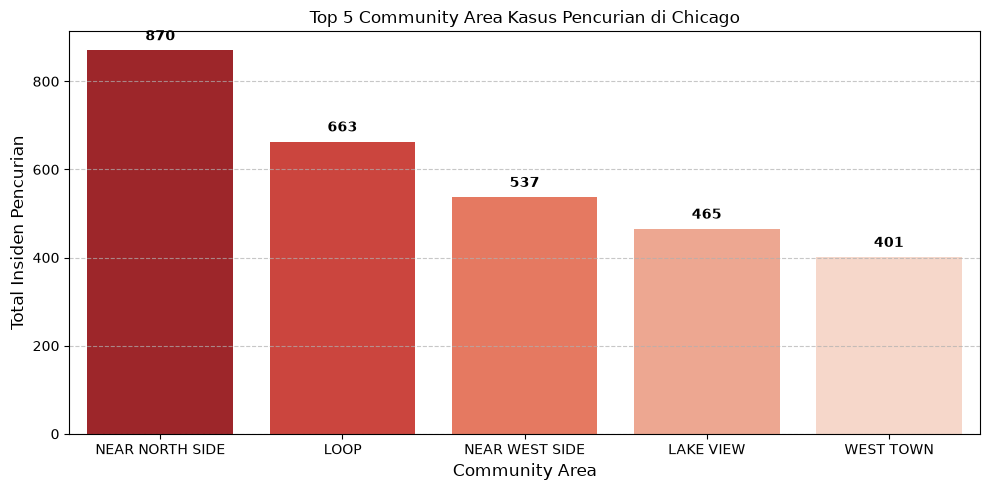

Top 3 Tipe Lokasi Dominan di 5 Community Area Teratas


,community_area,community_name,location_description,total_cases
33,24,WEST TOWN,STREET,126
1,24,WEST TOWN,APARTMENT,42
32,24,WEST TOWN,SMALL RETAIL STORE,40
81,28,NEAR WEST SIDE,STREET,92
79,28,NEAR WEST SIDE,SMALL RETAIL STORE,57
40,28,NEAR WEST SIDE,APARTMENT,53
104,32,LOOP,DEPARTMENT STORE,145
120,32,LOOP,RESTAURANT,102
125,32,LOOP,SMALL RETAIL STORE,89
140,6,LAKE VIEW,DEPARTMENT STORE,73


Tabel Proyeksi Kasus Pencurian di November 2026


,community_area,community_name,area_proj_nov
0,8,NEAR NORTH SIDE,72
1,32,LOOP,55
2,28,NEAR WEST SIDE,45
3,6,LAKE VIEW,39
4,24,WEST TOWN,33


In [20]:
# Load CSV referensi kode wilayah Community Area
df_area_ref = pd.read_csv('CodeNum_Community_Areas.csv')

# Memastikan kolom kodenya string agar bisa di join di kedua df
df['community_area'] = df['community_area'].astype(float).astype(int).astype(str)
df_area_ref['community_area'] = df_area_ref['community_area'].astype(float).astype(int).astype(str)


# Menggabungkannya dengan dataframe utama (df)
df = df.merge(df_area_ref, on='community_area', how='left')

# Mengidentifikasi Top 5 Community Area dengan kasus pencurian terbanyak
top5_CA = (
    df.groupby(['community_area', 'community_name'])
    .size()
    .reset_index(name='total_cases')
    .sort_values('total_cases', ascending=False)
    .head(5)
)

#Visualisasi Bar Chart Top 5 Community Area
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=top5_CA, x='community_name', y='total_cases', palette='Reds_r')

# Menambahkan data label pada Bar Chart
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points'
                )

plt.title('Top 5 Community Area Kasus Pencurian di Chicago')
plt.xlabel('Community Area', fontsize = 12)
plt.ylabel('Total Insiden Pencurian', fontsize = 12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Filtering dataset khusus untuk Top 5 Community Area
top5_CA_list = top5_CA['community_area'].tolist()
df_top5 = df[df['community_area'].isin(top5_CA_list)]

# Rincian Top 3 Tipe Lokasi Tempat Kejadian (TKP) di 5 Community
top3_loc = (
    df_top5.groupby(['community_area', 'community_name', 'location_description'])
    .size()
    .reset_index(name='total_cases')
    .sort_values(['community_area', 'total_cases'], ascending=[True,False])
    .groupby(['community_area', 'community_name'])
    .head(3)
)

print('Top 3 Tipe Lokasi Dominan di 5 Community Area Teratas')
display(top3_loc)

#Hitung total kasus historis per kode wilayah dan nama wilayah nya
top5_proj_area_nov = (
    df.groupby(['community_area', 'community_name'])
    .size()
    .reset_index(name='total_history')
)

#Hitung total kasus historis per kode wilayah dan nama wilayah nya
top5_proj_area_nov = top5_proj_area_nov.sort_values('total_history', ascending=False).head(5)

#Hitung proporsi dan proyeksi kasus november 2026
top5_proj_area_nov['area_proj_nov'] = (
    ((top5_proj_area_nov['total_history']/len(df))* projection_nov)
    .round().
    astype(int)
    )

#Buat kolom proyeksi nov
table_proj_area_nov = top5_proj_area_nov[['community_area', 'community_name', 'area_proj_nov']].reset_index(drop=True)

print(f'Tabel Proyeksi Kasus Pencurian di November 2026')
display(table_proj_area_nov)

**Analisa dan Insight dari wilayah dan tipe lokasi dominan:**
1. **Top 5 Community Area Terawan**
    - *Near North Side* menduduki posisi paling atas sebagai wilayah paling rawan dengan 870 kasus, lalu *Loop* dengan 663 kasus, *Near West Side* dengan 537 kasus, *Lake View* dengan 465 kasus dan *West Town* dengan 401 kasus
    - Mayoritas kasus terpusat di kawasan pusat kota dan area urban yang dimana padat dengan penduduk yang ditandai dengan tingginya mobilitas penduduk serta area tersebut merupakan pusat aktivitas ekonomi/komersial terutama 3 community area teratas. --> *referensi didapatkan dari batasan zonasi resmi 77 community area milik pemerintah kota chicago (City of Chicago Data Portal)*

2. **Karakteristik Tipe Lokasi (TKP) Dominan:**
    - Area komersil dan ritel pada kawasan pusat bisnis seperti *Near North Side* dan Loop itu pencurian marak terjadi pada pertokoan dan tempat makan, seperti *Small Retail Store* (201 kasus di *Near North Side*), *Department Store* (145 kasus di wilayah *Loop*), serta *Restaurant* (88 kasus di *Near North Side* dan 102 kasus di *Loop*)
    - Jalanan publik pada wilayah *West Town* dan *Near West Side* dimana lokasi kejadian pencurian paling dominan terjadi, masing-masing dengan kasus sebanyak 126 dan 92 kasus.
    - Area pemukiman yaitu *Apartment* mencata angka pencurian paling tinggi pada area hunian di *Lake View* dan *West Town* dengan masing-masing kasus sebanyak 71 dan 42 kasus.

3. **Proyeksi Sebaran Kasus per Wilayah pada November 2026**
    - Berdasarkan estimasi proporsional terhadap total proyeksi bulanan (~831 kasus), *Near North Side* diproyeksikan tetap berada di posisi teratas dengan nilai 72 kasus
    - Wilayah lainnya diprediksi secara berurutan oleh *Loop* (55 kasus), *Near West Side* (45 kasus), *Lake View* (39 kasus), *West Town* (33 kasus).
    - Hasil ini sejalan dengan histori dalam 1 tahun terakhir sehingga implikasi nya disarankan untuk memprioritaskan kawasan ritel dan area jalan publik pada bulan November di wilayah *Near North Side* dan *Loop* untuk meredan konsentrasi utama potensi kejahatan.

Setelah memetakan wilayah area rawan pada *Community Area* beserta tipe lokasi nya, kita telah memahami bagaimana distribusi geografi kejahatan. Kepolisian juga perlu sudut pandang evaluasi berkala secara agregat pada tiap kuartal (3 bulan) per tahunnya.

Analisis antar kuartal ini penting untuk mengidentidikasi tren musiman serta lonjakan tertinggi dalam kurun waktu 1 tahun terakhir sebagai dasar evaluasi efekvitas kebijakan dan alokasi sumber daya untuk kepolisian chicago.

### V.4 Analisis Perbandingan dan Pencurian Antar Kuartal
**Pertanyaan: Bagaiman perbandingan jumlah kasus pencurian antar kuartal dalam 1 tahun terakhir?**

Untuk menjawab pertanyaan ini kita harus mengekstrak komponen kuartal dari kolom 'date' menjadi variabel baru yaitu 'quarter'. Sehingga kita bisa mengagregasi total insiden di setiap kuartal dari Q1 hingga ke Q4 dan memvisualisasikannya menggunakan *Bar Chart* untuk melihat persentase kontribusi secara kuartal mana yang mengalami lonjakan pencurian terparah.

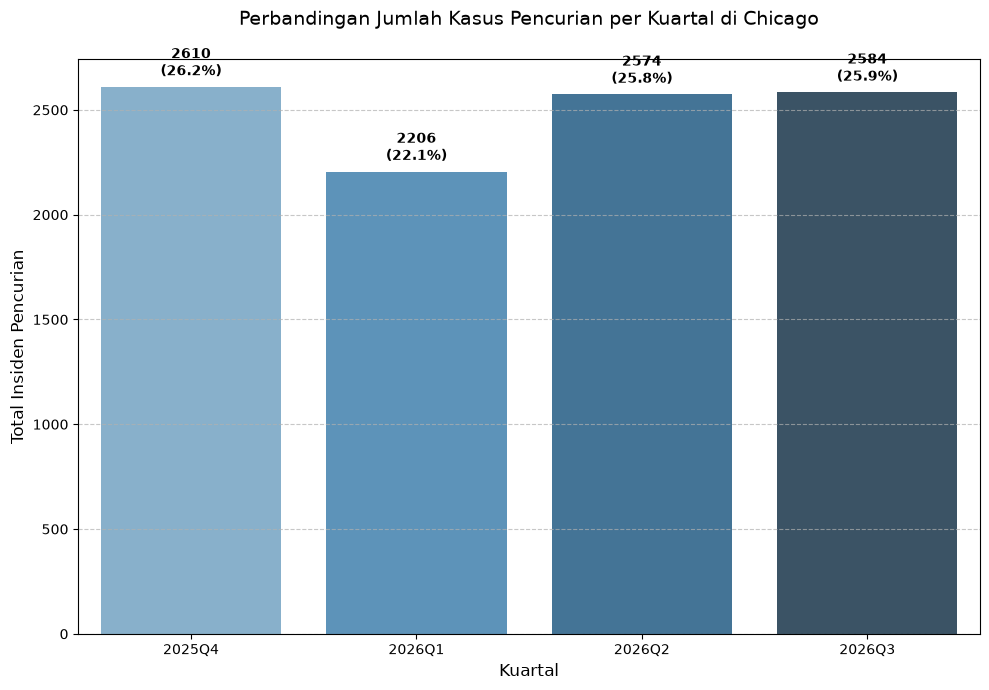

Ringkasan Kasus Pencurian per Kuartal


,quarter,total_cases,percentage
0,2025Q4,2610,26.168037
1,2026Q1,2206,22.117506
2,2026Q2,2574,25.807098
3,2026Q3,2584,25.907359


In [21]:
# Membuat kolom kuartal dari tanggal kejadian dan memastikan dia dalam bentuk string
df['quarter'] = df['date'].dt.to_period('Q').astype(str)

# Agregasi jumlah kasus per kuartal
q_cases = df.groupby('quarter').size().reset_index(name='total_cases')

# Menghitung persentase kontribusi kasus per kuartal
q_cases['percentage'] = (q_cases['total_cases']/q_cases['total_cases'].sum()) *100

# Visualisasi Bar Chart untuk perbandingan per kuartal
plt.figure(figsize=(10, 7))
ax = sns.barplot(data=q_cases, x='quarter', y='total_cases', palette='Blues_d')

# Menambahkan data label pada Bar Chart
for p in ax.patches:
    height = p.get_height()
    pct = (height / q_cases['total_cases'].sum()) * 100
    ax.annotate(f"{int(height)}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points'
                )

plt.title('Perbandingan Jumlah Kasus Pencurian per Kuartal di Chicago', fontsize=14, pad=25)
plt.xlabel('Kuartal', fontsize = 12)
plt.ylabel('Total Insiden Pencurian', fontsize = 12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Menampilkan ringkasan tabel kasus pencurian per kuartal
print('Ringkasan Kasus Pencurian per Kuartal')
display(q_cases)


**Analisa dan insight dari perbandingan kasus pencurian antar kuartal:**

1. **Puncak Kasus Kuartal**
    - Kuartal akhir tahun 2025 (**2025Q4**) mencatatkan angka pencurian tertinggi sebanyak 2610 kasus yaitu 26,1%. Poin ini diikuti oleh kuartal musim panas yaitu 2026Q3 sebanyak 2584 kasus dengan persentase 25,8% dan 2026Q2 dengan 2574 kasus dengan persentase 25,7%
    - Tingginya insiden Q4 sangat berkaitan dengan musim liburan akhir (*holiday season*) dan adanya peningkatan aktivitas perekonomian di pusat perbelanjaan. Sedangkan lonjakan Q2  dan Q3 pada tahun 2026 sesuai dengan asumsi awal kita yang dipicu oleh cuaca musim panas sehingga mobilitas ruang terbuka lebih banyak

2. **Penurunan di Kuartal Pertama**
    - Kuartal pertama (**2026Q1**) mengalami penurunan jumlah kasus menjadi 2206 kasus dengan persentase sebanyak 22,1%. Penurunan ini juga sesuai dengan asumsi kita dimana ini puncak musim dingin di Chicago --> (*referensi:https://id.climate-data.org/amerika-utara/amerika-serikat/illinois/chicago-1574/#climate-table*)

Setelah mengevaluasi tren agregat per kuartal, pihak kepolisian akan memerlukan analisis mengenai variabilitas harian pada lokasi paling rawan. Mengingat jalanan umu merupakan tipe lokasi dengan angka insiden tertinggi di berbagai wilayah, membedah sebaran kasus harian khusus di area publik akan membantu mendeteksi lonjakan ekstrem yang membutuhkan penanganan cepat.

### V.5 Analisis sebaran harian dan deteksi *outlier* di jalan publik (*street*)
**Pertanyaan: Bagaimana karakteristik sebaran dan tingkat fluktuasi harian kasus pencurian yang terjadi pada jalan publik (*street*)?**

Untuk menjawab pertanyaan ini kita akan memfilter dataset dengan location_description == 'STREET'. Lalu kita akan mengagregasikan total kasus pencurian harian berdasarkan kolom 'date' yang nantinya akan kita visualisasikan menggunakan diagram Boxplot dan pendekatan statistik IQR atau *Interquartile Range* untuk menentukan ambang batas atas serta mendeteksi tanggal-tangal kejadian yang mengalami lonjakan kasus secara tidak wajar (*outlier*)

Mean: 5.65 kasus
Median (Q2): 5.00 kasus
Standar Deviasi (std): 2.62 kasus
Nilai Mininum (Min): 1.00 kasus
Nilai Maximum (Max): 16.00 kasus
Kuartil 1 (Q1): 4.00 kasus
Kuartil 3 (Q3): 7.00 kasus
Ambang Batas Outlier: 11.50 kasus/hari
Kemiringan (Skewness): 0.65 kasus
Total Hari Outlier Terdeteksi: 11 hari



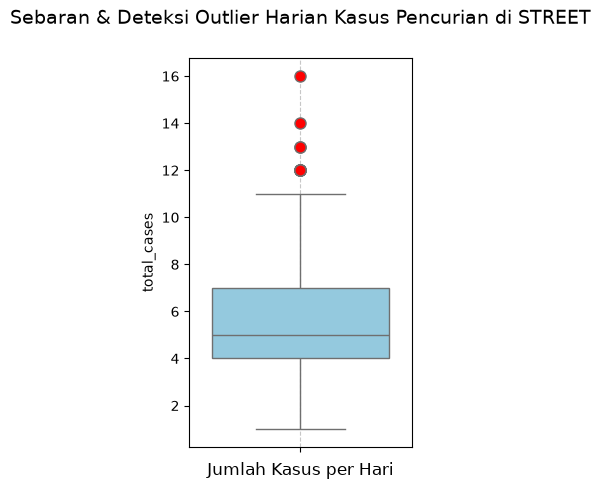

Tanggal dengan Lonjakan Ekstrem di STREET


,date,total_cases
26,2025-10-27,16
7,2025-10-08,14
226,2026-05-16,13
227,2026-05-17,13
16,2025-10-17,12
21,2025-10-22,12
30,2025-10-31,12
45,2025-11-15,12
191,2026-04-11,12
217,2026-05-07,12


In [22]:
# Memfilter data untuk lokasi 'STREET'
df_street = df[df['location_description'] == 'STREET']

# Agregasi jumlah kasus harian di STREET
daily_street = df_street.groupby(df_street['date'].dt.date).size().reset_index(name='total_cases')

# Menghitung Statistik IQR untuk deteksi outlier dan statistik deskriptif lengkap
mean_val = daily_street['total_cases'].mean()
median_val = daily_street['total_cases'].median()
std_val = daily_street['total_cases'].std()
min_val = daily_street['total_cases'].min()
max_val = daily_street['total_cases'].max()

Q1 = daily_street['total_cases'].quantile(0.25)
Q3 = daily_street['total_cases'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + (1.5 * IQR)
skew_val = daily_street['total_cases'].skew()

# Filtering tanggal dengan status outlier
outliers = daily_street[daily_street['total_cases'] > upper_bound].sort_values('total_cases', ascending=False)

#Menampilkan Ringkasan statistik deskriptif
print(f'Mean: {mean_val:.2f} kasus')
print(f'Median (Q2): {median_val:.2f} kasus')
print(f'Standar Deviasi (std): {std_val:.2f} kasus')
print(f'Nilai Mininum (Min): {min_val:.2f} kasus')
print(f'Nilai Maximum (Max): {max_val:.2f} kasus')
print(f'Kuartil 1 (Q1): {Q1:.2f} kasus')
print(f'Kuartil 3 (Q3): {Q3:.2f} kasus')
print(f'Ambang Batas Outlier: {upper_bound:.2f} kasus/hari')
print(f'Kemiringan (Skewness): {skew_val:.2f} kasus')
print(f'Total Hari Outlier Terdeteksi: {len(outliers)} hari\n')

# Visualisasi boxplot sebaran harian di lokasi STREET
plt.figure(figsize=(3, 5))
sns.boxplot(data=daily_street, y='total_cases', color='skyblue', flierprops={'markerfacecolor':'red', 'marker':'o', 'markersize':8})

plt.title('Sebaran & Deteksi Outlier Harian Kasus Pencurian di STREET', fontsize=14, pad=25)
plt.xlabel('Jumlah Kasus per Hari', fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#Menampilkan tabel tanggal dari outlier
print('Tanggal dengan Lonjakan Ekstrem di STREET')
display(outliers)


**Analisa dan insight dari statistik deskriptif dan deteksi oulier harian (*STREET*):**

1. **Evaluasi Ukuran Pemusatan dan Sebaran Data**
    - *Central Tendency* dimana rata-rata *mean* kasus pencurian harian di jalan publik berada di angka 6 kasus/hari (presisi statistik: 5,64), dengan nilai tengah sebesar 5 kasus/hari. Selisih tipis ini menunjukkan bahwa adanya beberapa hari tertentu yang mencatatkan lonjakan kasus di atas rata-rata. 
    - Ukuran sebaran atau nilai IQR berada di angka 3 kasus (rentang *Q1* = 4 kasus hingga *Q3* = 7 kasus/hari) dengan standar deviasi sebesar 2,62. Secara operasional, frekuensi pencurian harian di jalan publik pada kondisi normal memiliki data yang stabil di kisaran 4 hingga 7 kasus.
    -  Bentuk distribusi dari skewness bernilai positif 0,65 mengonfirmasi bahwa distribusi data harian miring ke kanan, tandanya mayoritas hari memiliki tingkat kejahatan rendah hingga sedang, namun terdapat ekor distribusi akibat beberapa hari dengan lonjakan insiden ekstrem.

2. **Evaluasi Lonjakan Ekstrem**
    - Berdasarkan model statistik IQR dengan ambang batas $11,50$, secara praktis setiap hari yang mencatatkan **12 kasus/lebih** dikategorikan sebagai lonjakan tidak wajar (*outlier*)
    - Terdeteksi ada 11 hari *outlier* di mana angka pencurian di jalan publik melampaui batas wajar. Lonjakan tertinggi terjadi pada tanggal 27 Oktober 2025 yaitu terdapat 16 kasus dan 8 Oktober 2025 sebanyak 14 kasus, disusul dengan tanggal 16 dan 17 Mei sebanyak 13 kasus pada masing-masing hari

*Lonjakan harian ini mengindikasikan pemicu eksternal khusus mungkin acara publik, festial, atau titik lemah pengawasan patroli yang memerlukan perhatian taktis serta alokasi personel ekstra oleh kepolisian chicago.*



### V.6 Analisis Statistik Inferensial dalam Perbedaan *Arrest Rate* Lokasi Publik dan Privat
**Pertanyaan: Apakah ada perbedaan signifikan pada *Arreset Rate* antara lokasi publik (*street/sidewalk*) dengan lokasi Privat (*residence/apartments*)?**

Untuk menjawab pertanyaan diperlukan metode statistik inferensial dan kita akan menggunakan **Uji Chi-Square Independensi (*Chi-Square Test of Independence*)** dikarenakan kedua variabel bersifat kategorikal kualitatif dimana 'location_type' dan 'arrest' (True|Tertangkap vs False|Tidak Tertangkap). Oleh sebab itu Uji *Chi-Square* sangat ideal untuk mengevaluasi apakah proporsi keberhasilan penangkapan bergantung secara signifikan dengan jenis lokasi kejadian (tabel kontingensi $2\times2$). Data independen akan diambil dari sampel insiden di lokasi publik dan privat yang merupakan dua kelompok pengamatan terpisah dan saling bebas

#### Rumusan Hipotesis dan Kriteria Keputusan
***Case*: Korelasi antara kategori lokasi dengan status penangkapan**
**1. Rumusan hipotesis:**
- **$H_0$:** Tidak ada hubungan yang signifikan antara kategori lokasi (Publik vs Privat) dengan status penangkapan (*Arrest Rate*)
- **$H_1$:** Ada hubungan yang signifikan antara kategori lokasi (Publik vs Privat) dengan status penangkapan (*Arrest Rate*)

**2. Tingkat signifikansi (*Significance Level*):**
- $\alpha = 0,05$ (Tingkat kepercayaan $95\%$)

**3. Aturan Pengambilan Keputusan (*Decision Rule*):**   
- Jika *p-value* $< 0,05$ $\rightarrow$ Tolak $H_0$ Terbukti ada hubungan yang signifikan secara statistik antara tipe lokasi dengan *arrest rate*
- Jika *p-value*  $\ge 0,05$ $\rightarrow$ Gagal Tolak $H_0$ Tidak adanya hubungan yang signifikan secara statistik antara tipe lokasi dengan *arrest rate*

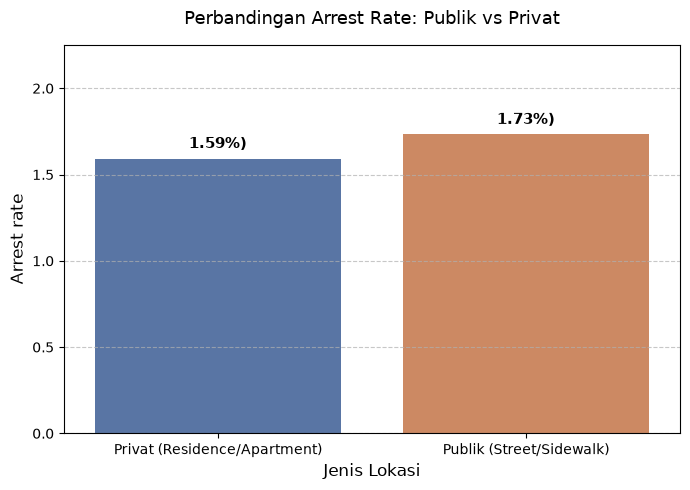

TABEL KONTINGENSI


arrest,False,True
location_type,,
Privat (Residence/Apartment),2101,34
Publik (Street/Sidewalk),2326,41


P-value: 0.8034034843423998
HASIL UJI CHI-SQUARE
P-value: 0.8034
P-Value (0.8034) >= Critical Value (0.05)
Keputusan: Gagal tolak H0 (Failed to reject H0)
kesimpulan: Tidak ada hubungan yang signifikan antara tipe lokasi dengan arrest rate


In [23]:
#Membuat definisi baru antara lokasi Publik dan lokasi Privat
pub_loc = ['STREET', 'SIDEWALK']
pri_loc = ['RESIDENCE', 'APARTMENT']

#Filter dataset utama untuk membuat dataframe subset
df_kq6 = df [df['location_description'].isin(pub_loc + pri_loc)].copy()

#Fungsi pengelompokan ke kolom 'location_type'
def categorize_location(loc):
    if loc in pub_loc:
        return 'Publik (Street/Sidewalk)'
    return 'Privat (Residence/Apartment)'

df_kq6['location_type'] = df_kq6['location_description'].apply(categorize_location)

# Menghitung persentase arrest rate untuk dengan mean
arrest_sum = (df_kq6.groupby('location_type')['arrest'].mean() * 100).reset_index(name='arrest_rate')

#Visualisasi Bar Chart
plt.figure(figsize=(7,5))
ax = sns.barplot(data=arrest_sum, x='location_type', y='arrest_rate', palette=['#4C72B0', '#DD8452'])

#Label persentase dan teks diatas grafik
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5), textcoords='offset points'
                )

plt.title('Perbandingan Arrest Rate: Publik vs Privat', fontsize=13, pad=15)
plt.xlabel('Jenis Lokasi', fontsize = 12)
plt.ylabel('Arrest rate', fontsize = 12)
plt.ylim(0, max(arrest_sum['arrest_rate']) * 1.3)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#Membuat Tabel Kontingensi antara tipe lokasi dan status penangkapan
contingency_table = pd.crosstab(df_kq6['location_type'],df_kq6['arrest'])
print ('TABEL KONTINGENSI')
display(contingency_table)

# Menjalankan Uji Chi-Square Independensi
res = stats.chi2_contingency(contingency_table)
p_val = res.pvalue
print('P-value:', res.pvalue)

print('HASIL UJI CHI-SQUARE')
print(f'P-value: {p_val:.4f}')

critical_value = 0.05
if p_val < critical_value:
    print(f'P-Value ({p_val:.4f}) < Critical Value ({critical_value})')
    print('Keputusan: Tolak H0 (H0 Rejected)')
    print('kesimpulan: Terdapat hubungan yang signifikan antara tipe lokasi dengan arrest rate')
else:
    print(f'P-Value ({p_val:.4f}) >= Critical Value ({critical_value})')
    print('Keputusan: Gagal tolak H0 (Failed to reject H0)')
    print('kesimpulan: Tidak ada hubungan yang signifikan antara tipe lokasi dengan arrest rate')

**Analisa dan insight dari statistik deskriptif dan deteksi oulier harian (*STREET*):**

1. **Hasil Evaluasi Hipotesis dan Statistik**
    - Tingkat penangkapan di lokasi publik (Street/Sidewalk) tercatat sebesar 1,73% (41 penangkapan dari 2375 kasus), sedangkan di lokasi privat (Residence/Apartment) sebesar 1,59% (34 penangkapan dari 2138 kasus)
    - Nilai P-Value: Uji Chi-Square menghasilkan p-value sebesar 0,8100
    - Keputusan statistik karena p-value (0,8100)  $\ge Critical Value (0,05)$ , keputusannya adalah gagal tolak $H_0$

2. **Temuan Utama (*Key Findings*)**
    - Secara statistik, tidak ada hubungan yang signifikan antara kategori lokasi kejadian (Publik vs Privat) dengan tingkat keberhasilan penangkapan pelaku pencurian (*arrest rate*)
    - Selisih persentase yang sangat kecil sebesar **0,14%** antara lokasi publik dan privat terbukti secara statistik bukan sebagai perbedaan efektivitas, melainkan sekadar variasi yang acak pada sampel data.

3. **Implikasi Operasional Kepolisian**
    - Tingkat penyelesaian kasus (*Arrest rate*) yang tergolong sangat rendah di kedua tingkat kategori sektor (<2%) menunjukkan bahwa kendala utama pada kepolisian chicago tidak disebabkan oleh aksesibilitas wilayah kejadian
    - Kepolisian chicago perlu lebih fokus evaluasi pada strategi penindakan seperti peningkatan sistem pengawasan terpadu, evaluasi jadwal patroli pada jam dan titik rawan, optimalisasi waktu respon laporan untuk meningkatkan angka penangkapan di seluruh jenis lokasi (publik maupun privat). 


## VI. PENGAMBILAN KESIMPULAN
- Tren musiman kasus pencurian di Kota Chicago menunjukkan pola fluktuasi musiman yang terkait dengan suhu dan mobilitas publik. Angka insiden tertinggi konsisten terjadi pada bulan-bulan berudara hangat seperti Oktober (937 kasus), Mei (931 kasus), dan Agustus (907 kasus). Sedangkan titik terendah berada pada puncak musim dingin di bulan Februari (667 kasus)
- Proyeksi kasus untuk bulan November 2026 menggunakan kalkulasi *statistical baseline*, total kasus mengalami diproyeksikan sampai ~831 kasus dengan titik sebaran rawan pada 5 *Community Area* utama yaitu *Near North Side* (72 kasus), *Loop* (55 kasus), *Near West Side* (45 kasus), *Lake View* (39 kasus), *West Town* (33 kasus).
- Karakteristik tempat kejadian dan waktu rawan didominasi oleh kawasan komersial seperti (*Small Retail Store & Department Store*) serta jalanan umum (*Street*) dengan puncak jam rawan yang konsisten terjadi pada siang hingga sore hari (12:00-18:00) terutama menjelang akhir pekan yaitu hari Jumat dan Sabtu.
- Alokasi sumber daya untuk mengintervensi patroli tidak efisien jika disebar secara merata sepanjang tahun. Target penurunan angka pencurian sebesar 10% lebih realistis dicapai dengan memfokuskan pengerahan personel pada koridor komersial di area *Near North Side* dan *Loop* khusus di jendela waktu kritis 12:00-18:00 guna meredam proyeksi kasus di bulan November 2026

***Kode cell dibawah hanya untuk memastikan bahwa DataFrame untuk Tableau Public bersih***

In [24]:
# Membuat Dataframe Untuk Tableau Public
df.to_csv('chicago_theft_bersih.csv', index=False)

# Mengecek apakah csv sudah bersih apa belum
df_cek = pd.read_csv('chicago_theft_bersih.csv')
print('Missing Values')
df_cek.isnull().sum()

print('Duplicates')
df_cek.duplicated().sum()

df_cek.info()

print('Summary Statistics')
df_cek.describe()

print('Top 10 Location')
df_cek['location_description'].value_counts().head(10)

Missing Values
Duplicates
<class 'pandas.DataFrame'>
RangeIndex: 9974 entries, 0 to 9973
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   unique_key            9974 non-null   int64  
 1   case_number           9974 non-null   str    
 2   date                  9974 non-null   str    
 3   block                 9974 non-null   str    
 4   primary_type          9974 non-null   str    
 5   location_description  9974 non-null   str    
 6   arrest                9974 non-null   bool   
 7   district              9974 non-null   int64  
 8   ward                  9974 non-null   float64
 9   community_area        9974 non-null   int64  
 10  month                 9974 non-null   str    
 11  day_name              9974 non-null   str    
 12  hour                  9974 non-null   int64  
 13  community_name        9974 non-null   str    
 14  quarter               9974 non-null   str    
dtypes: boo

location_description
STREET                                    2052
APARTMENT                                 1372
SMALL RETAIL STORE                        1081
DEPARTMENT STORE                           886
RESIDENCE                                  763
RESIDENCE - PORCH / HALLWAY                347
RESTAURANT                                 326
PARKING LOT / GARAGE (NON RESIDENTIAL)     318
SIDEWALK                                   315
GROCERY FOOD STORE                         292
Name: count, dtype: int64